# Step 9 — Ethereum: sufficienza predittiva dello stato

Verifichiamo se lo stato proposto perde informazione utile alla previsione di utilizzo e log priority fee p50.
Tre periodi distinti aiutano a distinguere miglioramenti locali da risultati coerenti nel tempo.

**Risultati eseguiti.** I lag fino a 10 riducono il MSE testing di log p50 del 6,94%, 6,19% e 13,18%. Per X i benefici sono più piccoli e cambiano fra periodi e fasce; nel primo periodo compaiono tre previsioni fuori da [0, 2]. Rimane dipendenza residua: dettagli e limiti in [findings.md](findings.md).

[Checklist, punto 9](../../../../docs/math_dev/ethereum_eip1559_optimal_stopping_summary.md).
Fonte: artefatti verificati dello [step 1](../step1/dataset_ethereum.ipynb), senza modificare il dataset.
Questi modelli della media sono diagnostici: non costituiscono un kernel congiunto validato, né una prova della proprietà di Markov.

**Allineamento.** Al decision origin dopo il closed parent `n−1`, `B_n` è già ricostruibile esattamente da EIP-1559.
Le risposte sono `X_n` e `Y_n = log(1 + P50_n in wei/gas)`; il baseline usa `log(B_n in wei/gas)`, `X_{n−1}`, `Y_{n−1}`.
Le fee incluse ponderate per gas non garantiscono il prezzo di inclusione di una nuova transazione.

## Ambiente, finestre e protocollo di valutazione

Carichiamo la fonte e fissiamo tre finestre contigue disgiunte da 30000 blocchi, con ruoli temporali separati.
Le prime dieci righe servono ai lag: tutti i modelli condividono 19990 target training, 5000 validation e 5000 testing.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from scipy.stats import chi2
from statsmodels.stats.diagnostic import acorr_ljungbox

project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/CONTEXT.md").is_file()
)
sys.path.insert(0, str(project_root / "src"))
from kairos.temporal import _forming_child_base_fee  # noqa: E402 (checkout locale)

input_directory = project_root / "outputs/notebook_diagnostics/ethereum/step1"
summary = json.loads((input_directory / "preprocessing_summary.json").read_text())
df = pd.read_parquet(input_directory / "ethereum_blocks_diagnostics.parquet")
assert summary["chain_id"] == 1
assert summary["dataset_id"] == "e7b17cfb-320d-4e6c-93c1-06dbc24f312d"
assert len(df) == summary["rows"] and np.all(np.diff(df.block_number) == 1)
output_directory = project_root / "outputs/notebook_diagnostics/ethereum/step9"
output_directory.mkdir(parents=True, exist_ok=True)
WINDOW = 30000
MAX_LAG = 10
TRAIN = 20000 - MAX_LAG
VALID_END = 25000 - MAX_LAG
ROLLING_WINDOW = 10000
REFIT = 1000
HAC_LAGS = 50
starts = {"inizio": 0, "centro": (len(df) - WINDOW) // 2, "fine": len(df) - WINDOW}
assert all(
    b - a >= WINDOW
    for a, b in zip(list(starts.values())[:-1], list(starts.values())[1:], strict=True)
)
responses = {"X": "X", "log_p50": "log_effective_priority_fee_per_gas_p50"}
baseline_columns = ["known_log_base_fee", "X_lag1", "P_lag1"]
windows = {}
scope_rows = []
for name, start in starts.items():
    part = df.iloc[start : start + WINDOW].reset_index(drop=True)
    frame = part[["block_number", "timestamp", *responses.values()]].copy()
    # B_n usa soltanto base fee e gas del closed parent n-1.
    predicted_fee = np.fromiter(
        (
            _forming_child_base_fee(int(b), int(g), int(limit))
            for b, g, limit in part[["base_fee_per_gas", "gas_used", "gas_limit"]]
            .iloc[:-1]
            .itertuples(index=False, name=None)
        ),
        dtype=np.int64,
        count=WINDOW - 1,
    )
    assert np.array_equal(predicted_fee, part.base_fee_per_gas.to_numpy()[1:])
    frame["known_log_base_fee"] = np.r_[np.nan, np.log(predicted_fee)]
    for lag in range(1, MAX_LAG + 1):
        frame[f"X_lag{lag}"] = part.X.shift(lag)
        frame[f"P_lag{lag}"] = part[responses["log_p50"]].shift(lag)
    frame["tx_lag1"] = np.log1p(part.tx_count).shift(1)
    # La matrice NumPy richiede float, non il nullable Int64 del Parquet.
    frame["interval_lag1"] = part.block_interval.shift(1).astype(float)
    frame = frame.iloc[MAX_LAG:].reset_index(drop=True)
    assert frame.notna().all().all()
    np.testing.assert_array_equal(frame.X_lag1, part.X.iloc[MAX_LAG - 1 : -1])
    np.testing.assert_array_equal(frame.P_lag10, part[responses["log_p50"]].iloc[:-MAX_LAG])
    frame["role"] = np.where(
        frame.index < TRAIN, "training", np.where(frame.index < VALID_END, "validation", "testing")
    )
    windows[name] = frame
    for role, group in frame.groupby("role", sort=False):
        scope_rows.append(
            {
                "periodo": name,
                "role": role,
                "n_target": len(group),
                "primo_blocco": int(group.block_number.iloc[0]),
                "ultimo_blocco": int(group.block_number.iloc[-1]),
                "inizio_UTC": pd.to_datetime(group.timestamp.iloc[0], unit="s", utc=True),
                "fine_UTC": pd.to_datetime(group.timestamp.iloc[-1], unit="s", utc=True),
            }
        )
scope = pd.DataFrame(scope_rows)
scope.to_csv(output_directory / "analysis_windows.csv", index=False)
display(scope)
plt.rcParams.update(
    {
        "figure.figsize": (11, 4),
        "font.size": 11,
        "axes.grid": True,
        "grid.alpha": 0.2,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 24)
print("Fee originali: wei/gas; log base fee naturale; log p50 con log1p; intervallo: secondi.")

,periodo,role,n_target,primo_blocco,ultimo_blocco,inizio_UTC,fine_UTC
0,inizio,training,19990,23935704,23955693,2025-12-03 21:51:47+00:00,2025-12-06 18:45:35+00:00
1,inizio,validation,5000,23955694,23960693,2025-12-06 18:45:47+00:00,2025-12-07 11:35:23+00:00
2,inizio,testing,5000,23960694,23965693,2025-12-07 11:35:35+00:00,2025-12-08 04:25:23+00:00
3,centro,training,19990,24747972,24767961,2026-03-27 09:22:23+00:00,2026-03-30 04:14:47+00:00
4,centro,validation,5000,24767962,24772961,2026-03-30 04:14:59+00:00,2026-03-30 20:59:59+00:00
5,centro,testing,5000,24772962,24777961,2026-03-30 21:00:11+00:00,2026-03-31 13:42:47+00:00
6,fine,training,19990,25560240,25580229,2026-07-18 14:39:23+00:00,2026-07-21 09:34:11+00:00
7,fine,validation,5000,25580230,25585229,2026-07-21 09:34:23+00:00,2026-07-22 02:17:35+00:00
8,fine,testing,5000,25585230,25590229,2026-07-22 02:17:47+00:00,2026-07-22 19:02:47+00:00


Fee originali: wei/gas; log base fee naturale; log p50 con log1p; intervallo: secondi.


## 1. Modello baseline sullo stato proposto

Stimiamo una media lineare di X e log p50 usando esclusivamente lo stato disponibile dopo il closed parent.
Ljung–Box sui residui training verifica se rimane dipendenza che motivi la ricerca di lag più vecchi.

In [2]:
models = {}
specifications = {}
comparison_rows = []
coefficient_rows = []
diagnostic_rows = []


def fit_candidate(period, response, specification, columns):
    frame = windows[period]
    training = frame.iloc[:TRAIN]
    design = sm.add_constant(training[columns], has_constant="add")
    fit = sm.OLS(training[responses[response]], design).fit()
    assert fit.df_model == len(columns), "Regressori collineari: confronti non identificati"
    robust = fit.get_robustcov_results(cov_type="HAC", maxlags=HAC_LAGS)
    key = (period, response, specification)
    models[key] = fit
    specifications[key] = columns
    added = [c for c in columns if c not in baseline_columns]
    lr = lr_p = wald_p = np.nan
    if added:
        base = models[period, response, "baseline"]
        assert fit.nobs == base.nobs
        lr = max(0.0, 2 * (fit.llf - base.llf))
        lr_p = chi2.sf(lr, len(added))
        restriction = np.eye(len(design.columns))[[design.columns.get_loc(c) for c in added]]
        wald_p = float(robust.wald_test(restriction, scalar=True).pvalue)
    comparison_rows.append(
        {
            "periodo": period,
            "risposta": response,
            "specifica": specification,
            "n_training": int(fit.nobs),
            "AIC": fit.aic,
            "BIC": fit.bic,
            "LR_Gaussian_vs_baseline": lr,
            "LR_Gaussian_p": lr_p,
            "Wald_HAC_aggiunte_p": wald_p,
        }
    )
    interval = robust.conf_int()
    for i, column in enumerate(design.columns):
        coefficient_rows.append(
            {
                "periodo": period,
                "risposta": response,
                "specifica": specification,
                "regressore": column,
                "coefficiente": robust.params[i],
                "SE_HAC": robust.bse[i],
                "p_HAC": robust.pvalues[i],
                "CI95_low": interval[i, 0],
                "CI95_high": interval[i, 1],
            }
        )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)
        lb = acorr_ljungbox(fit.resid, lags=[5, 10, 20, 50], return_df=True)
    for lag, row in lb.iterrows():
        diagnostic_rows.append(
            {
                "periodo": period,
                "risposta": response,
                "specifica": specification,
                "role": "training_in_sample",
                "lag": lag,
                "LB_stat": row.lb_stat,
                "LB_p": row.lb_pvalue,
            }
        )
    return fit


for period in windows:
    for response in responses:
        fit_candidate(period, response, "baseline", baseline_columns)
display(pd.DataFrame(comparison_rows).round(5))
display(pd.DataFrame(diagnostic_rows).query("lag == 50").round(5))

,periodo,risposta,specifica,n_training,AIC,BIC,LR_Gaussian_vs_baseline,LR_Gaussian_p,Wald_HAC_aggiunte_p
0,inizio,X,baseline,19990,29924.44077,29956.05272,NaN,NaN,NaN
1,inizio,log_p50,baseline,19990,107032.35282,107063.96477,NaN,NaN,NaN
2,centro,X,baseline,19990,27743.26044,27774.87239,NaN,NaN,NaN
3,centro,log_p50,baseline,19990,122853.16695,122884.77890,NaN,NaN,NaN
4,fine,X,baseline,19990,26506.22273,26537.83468,NaN,NaN,NaN
5,fine,log_p50,baseline,19990,85910.01740,85941.62935,NaN,NaN,NaN


,periodo,risposta,specifica,role,lag,LB_stat,LB_p
3,inizio,X,baseline,training_in_sample,50,409.94950,0.0
7,inizio,log_p50,baseline,training_in_sample,50,1994.83925,0.0
11,centro,X,baseline,training_in_sample,50,267.33575,0.0
15,centro,log_p50,baseline,training_in_sample,50,10416.61894,0.0
19,fine,X,baseline,training_in_sample,50,376.83112,0.0
23,fine,log_p50,baseline,training_in_sample,50,2148.33889,0.0


## 2. Informazione aggiunta da X al lag 2

Aggiungiamo X del penultimo blocco chiuso mantenendo identici target e altre informazioni.
Il test Wald HAC valuta il contributo condizionato; il vantaggio predittivo sarà misurato fuori campione.

In [3]:
for period in windows:
    for response in responses:
        fit_candidate(period, response, "X_lag2", baseline_columns + ["X_lag2"])
display(pd.DataFrame(comparison_rows).query("specifica == 'X_lag2'").round(5))

,periodo,risposta,specifica,n_training,AIC,BIC,LR_Gaussian_vs_baseline,LR_Gaussian_p,Wald_HAC_aggiunte_p
6,inizio,X,X_lag2,19990,29712.87764,29752.39258,213.56313,0.00000,0.00000
7,inizio,log_p50,X_lag2,19990,107029.59625,107069.11119,4.75657,0.02919,0.04620
8,centro,X,X_lag2,19990,27625.25712,27664.77206,120.00332,0.00000,0.00000
9,centro,log_p50,X_lag2,19990,122851.38157,122890.89650,3.78539,0.05170,0.06651
10,fine,X,X_lag2,19990,26397.98793,26437.50286,110.23480,0.00000,0.00000
11,fine,log_p50,X_lag2,19990,85903.30033,85942.81527,8.71707,0.00315,0.02219


## 3. Informazione aggiunta dalla priority fee al lag 2

Aggiungiamo log p50 del penultimo blocco chiuso allo stesso baseline.
Il confronto mantiene separato il contributo delle fee da quello dell’utilizzo più vecchio.

In [4]:
for period in windows:
    for response in responses:
        fit_candidate(period, response, "P_lag2", baseline_columns + ["P_lag2"])
display(pd.DataFrame(comparison_rows).query("specifica == 'P_lag2'").round(5))

,periodo,risposta,specifica,n_training,AIC,BIC,LR_Gaussian_vs_baseline,LR_Gaussian_p,Wald_HAC_aggiunte_p
12,inizio,X,P_lag2,19990,29855.36840,29894.88334,71.07237,0.0,0.00000
13,inizio,log_p50,P_lag2,19990,106925.81615,106965.33109,108.53667,0.0,0.00000
14,centro,X,P_lag2,19990,27681.98572,27721.50066,63.27472,0.0,0.00000
15,centro,log_p50,P_lag2,19990,122464.14104,122503.65598,391.02591,0.0,0.00000
16,fine,X,P_lag2,19990,26479.04169,26518.55663,29.18104,0.0,0.00004
17,fine,log_p50,P_lag2,19990,85755.45875,85794.97369,156.55865,0.0,0.00000


## 4. Lag più vecchi motivati dai residui

Confrontiamo l’aggiunta congiunta dei lag 2 e, se Ljung–Box del baseline rifiuta al 5%, estendiamo fino a 5 e 10.
La griglia è fissata prima della validation; una selezione al bordo non dimostra che dieci lag siano sufficienti.

In [5]:
for period in windows:
    for response in responses:
        fit_candidate(period, response, "XP_lag2", baseline_columns + ["X_lag2", "P_lag2"])
        baseline_lb = next(
            row["LB_p"]
            for row in diagnostic_rows
            if row["periodo"] == period
            and row["risposta"] == response
            and row["specifica"] == "baseline"
            and row["lag"] == 50
        )
        if baseline_lb < 0.05:
            for last_lag in [5, 10]:
                columns = baseline_columns + [
                    f"{variable}_lag{lag}"
                    for lag in range(2, last_lag + 1)
                    for variable in ["X", "P"]
                ]
                fit_candidate(period, response, f"XP_lag{last_lag}", columns)
display(pd.DataFrame(comparison_rows).query("specifica.str.startswith('XP')").round(5))

,periodo,risposta,specifica,n_training,AIC,BIC,LR_Gaussian_vs_baseline,LR_Gaussian_p,Wald_HAC_aggiunte_p
18,inizio,X,XP_lag2,19990,29702.77204,29750.18997,225.66873,0.0,0.0
19,inizio,X,XP_lag5,19990,29537.72036,29632.55621,402.72042,0.0,0.0
20,inizio,X,XP_lag10,19990,29475.45413,29649.31985,484.98664,0.0,0.0
21,inizio,log_p50,XP_lag2,19990,106887.89596,106935.31389,148.45686,0.0,0.0
22,inizio,log_p50,XP_lag5,19990,106602.08255,106696.91840,446.27027,0.0,0.0
23,inizio,log_p50,XP_lag10,19990,106445.07992,106618.94564,623.27290,0.0,0.0
24,centro,X,XP_lag2,19990,27607.06774,27654.48566,140.19270,0.0,0.0
25,centro,X,XP_lag5,19990,27499.35999,27594.19584,259.90045,0.0,0.0
26,centro,X,XP_lag10,19990,27443.88026,27617.74599,335.38018,0.0,0.0
27,centro,log_p50,XP_lag2,19990,122379.09612,122426.51404,478.07084,0.0,0.0


## 5. Informazione aggiunta dal numero di transazioni

Aggiungiamo log1p del numero di transazioni del closed parent, senza usare il conteggio del target.
La trasformazione limita la scala e conserva i blocchi vuoti; nessuna riga viene esclusa.

In [6]:
for period in windows:
    for response in responses:
        fit_candidate(period, response, "tx_count", baseline_columns + ["tx_lag1"])
display(pd.DataFrame(comparison_rows).query("specifica == 'tx_count'").round(5))

,periodo,risposta,specifica,n_training,AIC,BIC,LR_Gaussian_vs_baseline,LR_Gaussian_p,Wald_HAC_aggiunte_p
36,inizio,X,tx_count,19990,29418.64851,29458.16345,507.79226,0.00000,0.00000
37,inizio,log_p50,tx_count,19990,106965.84712,107005.36205,68.50570,0.00000,0.00000
38,centro,X,tx_count,19990,27416.26621,27455.78114,328.99423,0.00000,0.00000
39,centro,log_p50,tx_count,19990,122791.68113,122831.19607,63.48582,0.00000,0.00000
40,fine,X,tx_count,19990,26464.94298,26504.45792,43.27975,0.00000,0.00000
41,fine,log_p50,tx_count,19990,85908.55277,85948.06771,3.46463,0.06269,0.17646


## 6. Informazione aggiunta dagli intervalli osservabili

Aggiungiamo t[n−1]−t[n−2], noto quando si chiude il parent n−1.
Non usiamo t[n]−t[n−1], che richiederebbe il timestamp futuro del blocco da prevedere.

In [7]:
for period, frame in windows.items():
    start = starts[period]
    original = df.iloc[start : start + WINDOW].reset_index(drop=True)
    np.testing.assert_array_equal(
        frame.interval_lag1, original.block_interval.iloc[MAX_LAG - 1 : -1]
    )
    for response in responses:
        fit_candidate(period, response, "interval", baseline_columns + ["interval_lag1"])
display(pd.DataFrame(comparison_rows).query("specifica == 'interval'").round(5))

,periodo,risposta,specifica,n_training,AIC,BIC,LR_Gaussian_vs_baseline,LR_Gaussian_p,Wald_HAC_aggiunte_p
42,inizio,X,interval,19990,29926.41927,29965.93421,0.02150,0.88342,0.90330
43,inizio,log_p50,interval,19990,107001.60416,107041.11910,32.74866,0.00000,0.00000
44,centro,X,interval,19990,27740.79242,27780.30736,4.46802,0.03453,0.02544
45,centro,log_p50,interval,19990,122853.57768,122893.09262,1.58927,0.20743,0.17797
46,fine,X,interval,19990,26501.24230,26540.75724,6.98043,0.00824,0.01269
47,fine,log_p50,interval,19990,85904.76789,85944.28283,7.24951,0.00709,0.00137


## 7. AIC, BIC, LR e previsioni rolling fuori campione

Confrontiamo likelihood gaussiane condizionate, Wald HAC e previsioni a un blocco ristimate solo sul passato.
La validation seleziona per MSE; il testing misura le specifiche già fissate e l’effetto della scelta, senza riselezionare.

In [8]:
# shortcut: media lineare diagnostica, usare un kernel vincolato per simulare X.
def rolling_forecast(values, design, start, stop):
    predictions = np.empty(stop - start)
    audit = []
    for first in range(start, stop, REFIT):
        last = min(first + REFIT, stop)
        fit_first = max(0, first - ROLLING_WINDOW)
        coefficient = np.linalg.lstsq(design[fit_first:first], values[fit_first:first], rcond=None)[
            0
        ]
        predictions[first - start : last - start] = design[first:last] @ coefficient
        audit.append((first, last - 1, fit_first, first - 1))
    return predictions, audit


# Modificare target non ancora osservati non deve cambiare previsioni precedenti.
check_values = np.sin(np.arange(200.0))
check_design = np.column_stack([np.ones(200), np.cos(np.arange(200.0))])
changed = check_values.copy()
changed[100:] = 999
np.testing.assert_allclose(
    rolling_forecast(check_values, check_design, 100, 150)[0],
    rolling_forecast(changed, check_design, 100, 150)[0],
)
assert all(
    fit_last < first
    for first, _, _, fit_last in rolling_forecast(check_values, check_design, 100, 150)[1]
)
comparison = pd.DataFrame(comparison_rows)
assert comparison.n_training.eq(TRAIN).all()
comparison.to_csv(output_directory / "model_comparison.csv", index=False)
pd.DataFrame(coefficient_rows).to_csv(output_directory / "training_coefficients.csv", index=False)
forecast_rows = []
audit_rows = []
selected = {}
for period, frame in windows.items():
    for response, column in responses.items():
        values = frame[column].to_numpy()
        candidates = [key[2] for key in specifications if key[:2] == (period, response)]
        validation_mse = {}
        for role, first, stop in [
            ("validation", TRAIN, VALID_END),
            ("testing", VALID_END, len(frame)),
        ]:
            for specification in candidates:
                columns = specifications[period, response, specification]
                design = sm.add_constant(frame[columns], has_constant="add").to_numpy()
                prediction, audit = rolling_forecast(values, design, first, stop)
                if role == "validation":
                    validation_mse[specification] = float(
                        np.mean((values[first:stop] - prediction) ** 2)
                    )
                residual = values[first:stop] - prediction
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore", FutureWarning)
                    lb = acorr_ljungbox(residual, lags=[5, 10, 20, 50], return_df=True)
                for lag, row in lb.iterrows():
                    diagnostic_rows.append(
                        {
                            "periodo": period,
                            "risposta": response,
                            "specifica": specification,
                            "role": role,
                            "lag": lag,
                            "LB_stat": row.lb_stat,
                            "LB_p": row.lb_pvalue,
                        }
                    )
                for a, b, fit_a, fit_b in audit:
                    assert fit_b < a
                    audit_rows.append(
                        {
                            "periodo": period,
                            "risposta": response,
                            "specifica": specification,
                            "role": role,
                            "primo_target_previsione": int(frame.block_number.iloc[a]),
                            "ultimo_target_previsione": int(frame.block_number.iloc[b]),
                            "primo_target_fit": int(frame.block_number.iloc[fit_a]),
                            "ultimo_target_fit": int(frame.block_number.iloc[fit_b]),
                        }
                    )
                forecast_rows.append(
                    pd.DataFrame(
                        {
                            "periodo": period,
                            "risposta": response,
                            "specifica": specification,
                            "role": role,
                            "block_number": frame.block_number.iloc[first:stop].to_numpy(),
                            "observed": values[first:stop],
                            "prediction": prediction,
                            "X_parent": frame.X_lag1.iloc[first:stop].to_numpy(),
                        }
                    )
                )
            if role == "validation":
                selected[period, response] = min(candidates, key=validation_mse.get)
forecasts = pd.concat(forecast_rows, ignore_index=True)
forecasts["squared_error"] = (forecasts.observed - forecasts.prediction) ** 2
forecasts["selected_on_validation"] = [
    spec == selected[period, response]
    for period, response, spec in zip(
        forecasts.periodo, forecasts.risposta, forecasts.specifica, strict=True
    )
]
scores = (
    forecasts.groupby(["periodo", "risposta", "specifica", "role"], sort=False)
    .agg(
        n=("squared_error", "size"),
        MSE=("squared_error", "mean"),
        selected_on_validation=("selected_on_validation", "first"),
    )
    .reset_index()
)
base_scores = scores[scores.specifica.eq("baseline")][["periodo", "risposta", "role", "MSE"]]
scores = scores.merge(
    base_scores.rename(columns={"MSE": "baseline_MSE"}),
    on=["periodo", "risposta", "role"],
    validate="many_to_one",
)
scores["MSE_gain_pct"] = 100 * (1 - scores.MSE / scores.baseline_MSE)
loss_rows = []
for (period, response, role), group in forecasts.groupby(["periodo", "risposta", "role"]):
    losses = group.pivot(index="block_number", columns="specifica", values="squared_error")
    for specification in losses:
        delta = losses.baseline - losses[specification]
        if specification == "baseline":
            mean_gain = low = high = 0.0
        else:
            loss_fit = sm.OLS(delta.to_numpy(), np.ones((len(delta), 1))).fit(
                cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS}
            )
            mean_gain = float(loss_fit.params[0])
            low, high = loss_fit.conf_int()[0]
        loss_rows.append(
            {
                "periodo": period,
                "risposta": response,
                "role": role,
                "specifica": specification,
                "mean_loss_gain": mean_gain,
                "CI95_HAC_low": low,
                "CI95_HAC_high": high,
            }
        )
scores = scores.merge(
    pd.DataFrame(loss_rows), on=["periodo", "risposta", "role", "specifica"], validate="one_to_one"
)
assert scores.n.eq(5000).all()
forecasts.to_parquet(output_directory / "rolling_predictions.parquet", index=False)
scores.to_csv(output_directory / "rolling_scores.csv", index=False)
pd.DataFrame(audit_rows).to_csv(output_directory / "rolling_refit_audit.csv", index=False)
pd.DataFrame(diagnostic_rows).to_csv(output_directory / "residual_diagnostics.csv", index=False)
display(scores.query("role == 'testing' and selected_on_validation").round(5))
print("LR/AIC/BIC: likelihood gaussiana di lavoro, sensibile alla misspecificazione.")
print("Wald e intervalli della differenza di perdita: HAC50; confronti multipli esplorativi.")

,periodo,risposta,specifica,role,n,MSE,selected_on_validation,baseline_MSE,MSE_gain_pct,mean_loss_gain,CI95_HAC_low,CI95_HAC_high
14,inizio,X,tx_count,testing,5000,0.36297,True,0.36399,0.27912,0.00102,-0.00213,0.00416
29,inizio,log_p50,XP_lag10,testing,5000,13.56649,True,14.57769,6.93661,1.01120,0.63920,1.38319
45,centro,X,XP_lag10,testing,5000,0.20776,True,0.21294,2.43022,0.00517,0.00135,0.00900
61,centro,log_p50,XP_lag10,testing,5000,17.38504,True,18.53312,6.19474,1.14808,0.82161,1.47454
77,fine,X,XP_lag10,testing,5000,0.15890,True,0.16090,1.23997,0.00200,0.00014,0.00385
93,fine,log_p50,XP_lag10,testing,5000,3.43507,True,3.95675,13.18459,0.52168,0.32806,0.71530


LR/AIC/BIC: likelihood gaussiana di lavoro, sensibile alla misspecificazione.
Wald e intervalli della differenza di perdita: HAC50; confronti multipli esplorativi.


## 8. Sufficienza dello stato nei periodi e nelle fasce di congestione

Confrontiamo gli effetti del modello scelto nei tre periodi e fra fasce di X del parent, con soglia al 95° percentile training.
Le fasce sono osservabili alla decisione; i risultati per fascia sono descrittivi e non definiscono regimi latenti o cause di mercato.

,periodo,risposta,fascia,soglia_X_training,specifica_scelta,n,baseline_MSE,selected_MSE,MSE_gain_pct
0,inizio,X,alta,1.99383,tx_count,264,0.34292,0.34082,0.61126
1,inizio,X,ordinaria,1.99383,tx_count,4736,0.36516,0.36420,0.26173
2,inizio,log_p50,alta,1.99383,XP_lag10,264,15.42109,13.95268,9.52207
3,inizio,log_p50,ordinaria,1.99383,XP_lag10,4736,14.53067,13.54496,6.78365
4,centro,X,alta,1.94291,XP_lag10,246,0.33727,0.33195,1.57519
5,centro,X,ordinaria,1.94291,XP_lag10,4754,0.20650,0.20134,2.50248
6,centro,log_p50,alta,1.94291,XP_lag10,246,25.56885,25.65412,-0.33350
7,centro,log_p50,ordinaria,1.94291,XP_lag10,4754,18.16905,16.95715,6.67013
8,fine,X,alta,1.96642,XP_lag10,133,0.29647,0.31779,-7.19062
9,fine,X,ordinaria,1.96642,XP_lag10,4867,0.15719,0.15456,1.67448


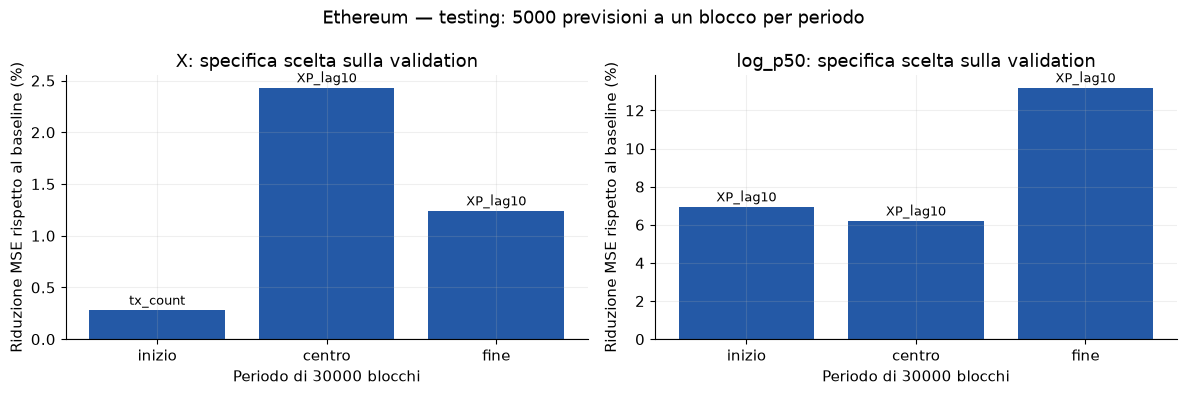

Barre: stime puntuali; gli IC HAC della differenza di perdita sono nella tabella precedente.


5786

In [9]:
regime_rows = []
thresholds = {}
for period, frame in windows.items():
    threshold = float(frame.X_lag1.iloc[:TRAIN].quantile(0.95))
    thresholds[period] = threshold
    for response in responses:
        chosen = selected[period, response]
        group = forecasts[
            (forecasts.periodo == period)
            & (forecasts.risposta == response)
            & (forecasts.role == "testing")
        ]
        group = group.copy()
        group["congestione_parent"] = np.where(group.X_parent >= threshold, "alta", "ordinaria")
        for regime, part in group.groupby("congestione_parent"):
            base = part[part.specifica.eq("baseline")].squared_error
            augmented = part[part.specifica.eq(chosen)].squared_error
            assert len(base) == len(augmented)
            regime_rows.append(
                {
                    "periodo": period,
                    "risposta": response,
                    "fascia": regime,
                    "soglia_X_training": threshold,
                    "specifica_scelta": chosen,
                    "n": len(base),
                    "baseline_MSE": base.mean(),
                    "selected_MSE": augmented.mean(),
                    "MSE_gain_pct": 100 * (1 - augmented.mean() / base.mean()),
                }
            )
regimes = pd.DataFrame(regime_rows)
regimes.to_csv(output_directory / "regime_comparison.csv", index=False)
display(regimes.round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, response in zip(axes, responses, strict=True):
    part = (
        scores[
            (scores.risposta == response)
            & scores.role.eq("testing")
            & scores.selected_on_validation
        ]
        .set_index("periodo")
        .loc[list(windows)]
    )
    ax.bar(part.index, part.MSE_gain_pct, color="#2459A6")
    ax.axhline(0, color="#444444", linewidth=0.8)
    ax.set(
        title=f"{response}: specifica scelta sulla validation",
        ylabel="Riduzione MSE rispetto al baseline (%)",
        xlabel="Periodo di 30000 blocchi",
    )
    for i, row in enumerate(part.itertuples()):
        ax.annotate(
            row.specifica,
            (i, row.MSE_gain_pct),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=9,
        )
fig.suptitle("Ethereum — testing: 5000 previsioni a un blocco per periodo")
fig.tight_layout()
plt.show()
plt.close(fig)
print(
    "Barre: stime puntuali; gli IC HAC della differenza di perdita sono nella tabella precedente."
)
selected_specs = [
    {
        "periodo": period,
        "risposta": response,
        "specifica": specification,
        "regressori": specifications[period, response, specification],
    }
    for (period, response), specification in selected.items()
]
provenance = {
    "dataset_id": summary["dataset_id"],
    "dataset_sha256": summary["dataset_sha256"],
    "source_doi": summary["source_doi"],
    "window_blocks": WINDOW,
    "max_lag": MAX_LAG,
    "training_target_rows": TRAIN,
    "validation_target_rows": 5000,
    "testing_target_rows": 5000,
    "rolling_window": ROLLING_WINDOW,
    "refit_every": REFIT,
    "HAC_lags": HAC_LAGS,
    "congestion_thresholds_training": thresholds,
    "base_fee_alignment": "B_n reconstructed exactly from closed parent n-1",
    "selection": "minimum validation MSE, candidates fixed from training diagnostics",
    "scope": scope.astype({"inizio_UTC": str, "fine_UTC": str}).to_dict("records"),
}
(output_directory / "analysis_scope.json").write_text(json.dumps(provenance, indent=2) + "\n")
(output_directory / "selected_specifications.json").write_text(
    json.dumps({**provenance, "selected": selected_specs}, indent=2) + "\n"
)

## Conclusione e limiti della verifica

Riepiloghiamo dimensione degli effetti, dipendenza residua e violazioni del supporto predetto senza certificare la proprietà di Markov.
Un’informazione aggiuntiva utile può motivare uno stato più ricco; non identifica da sola un processo latente o un kernel definitivo.

In [10]:
testing = scores[scores.role.eq("testing") & scores.selected_on_validation]
diagnostics = pd.DataFrame(diagnostic_rows)
chosen_diagnostics = diagnostics[diagnostics.role.eq("testing") & diagnostics.lag.eq(50)].copy()
chosen_diagnostics = chosen_diagnostics[
    [
        spec == selected[period, response]
        for period, response, spec in zip(
            chosen_diagnostics.periodo,
            chosen_diagnostics.risposta,
            chosen_diagnostics.specifica,
            strict=True,
        )
    ]
]
display(chosen_diagnostics.round(5))
support = (
    forecasts[(forecasts.risposta == "X") & forecasts.role.eq("testing")]
    .groupby(["periodo", "specifica"])
    .prediction.agg(outside_support=lambda x: int(((x < 0) | (x > 2)).sum()), n="size")
    .reset_index()
)
support.to_csv(output_directory / "X_prediction_support.csv", index=False)
display(support[support.outside_support.gt(0)])
print("Specifiche scelte:", selected)
print("Range guadagno MSE testing (%):", testing.MSE_gain_pct.min(), testing.MSE_gain_pct.max())
print("Le finestre coprono tre brevi periodi: nessun risultato dimostra la proprietà di Markov.")
print("Risultati:", output_directory)

,periodo,risposta,specifica,role,lag,LB_stat,LB_p
251,inizio,X,tx_count,testing,50,120.05890,0.00000
311,inizio,log_p50,XP_lag10,testing,50,82.79326,0.00243
375,centro,X,XP_lag10,testing,50,693.64532,0.00000
439,centro,log_p50,XP_lag10,testing,50,101.15822,0.00003
503,fine,X,XP_lag10,testing,50,82.58242,0.00255
567,fine,log_p50,XP_lag10,testing,50,507.06074,0.00000


,periodo,specifica,outside_support,n
23,inizio,tx_count,3,5000


Specifiche scelte: {('inizio', 'X'): 'tx_count', ('inizio', 'log_p50'): 'XP_lag10', ('centro', 'X'): 'XP_lag10', ('centro', 'log_p50'): 'XP_lag10', ('fine', 'X'): 'XP_lag10', ('fine', 'log_p50'): 'XP_lag10'}
Range guadagno MSE testing (%): 0.27911556768057677 13.184592238255687
Le finestre coprono tre brevi periodi: nessun risultato dimostra la proprietà di Markov.
Risultati: /Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/outputs/notebook_diagnostics/ethereum/step9
